# ASTR 5820 Problem Set 3

## 1. Build the Module

github repo: https://github.com/rhaliattar/astr5820.git

### test 1

Scale height at 1 AU: 0.033


Text(0.5, 1.0, 'Showing that $H/r \\propto r^{1/4}$')

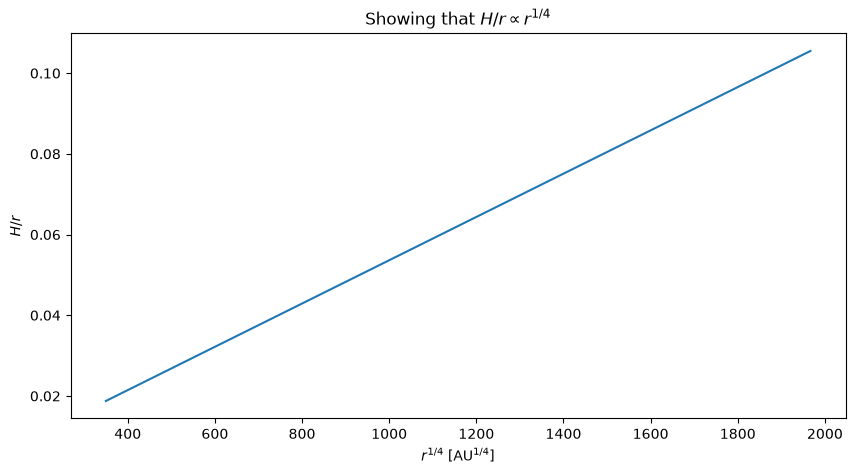

In [2]:
from astrotools.disk.structure import scale_height, temperature
from astrotools.constants import AU
import matplotlib.pyplot as plt
import numpy as np

H_at_1AU = scale_height(AU, temperature(AU))/AU # should be equal to 0.033

print(f"Scale height at 1 AU: {H_at_1AU:.3f}")
rs = np.linspace(0.1*AU, 100*AU, 1000)
H_over_r = scale_height(rs, temperature(rs))/rs

plt.figure(figsize = (10, 5))
plt.plot(rs**(1/4), H_over_r)
plt.xlabel(r'$r^{1/4}$ [AU$^{1/4}$]')
plt.ylabel(r'$H/r$')
plt.title(r'Showing that $H/r \propto r^{1/4}$')

### test 2

In [3]:
from astrotools.disk.structure import radial_grid, sed
from astrotools.constants import C_LIGHT, PC

r_edges = radial_grid(0.01*AU, 1e4*AU)
wavelengths = np.asarray([99e-6, 101e-6])
nus = C_LIGHT/wavelengths
distance = 1*PC # i'm assuming this shouldn't matter for the test we're running?

def T_func_3_over_4(r):
    return temperature(r, slope = -3/4)

def T_func_3_over_7(r):
    return temperature(r, slope = -3/7)

F_4 = sed(nus, r_edges, T_func_3_over_4, distance)
F_7 = sed(nus, r_edges, T_func_3_over_7, distance)
print(r'The local slope of $\nu F_{\nu}$ for $T \propto r^{-3/4}$ is', round((np.log(nus[1]*F_4[1])-np.log(nus[0]*F_4[0]))/(np.log(nus[1])-np.log(nus[0])), 3))
print(r'The local slope of $\nu F_{\nu}$ for $T \propto r^{-3/7}$ is', round((np.log(nus[1]*F_7[1])-np.log(nus[0]*F_7[0]))/(np.log(nus[1])-np.log(nus[0])), 3))

The local slope of $\nu F_{\nu}$ for $T \propto r^{-3/4}$ is 1.333
The local slope of $\nu F_{\nu}$ for $T \propto r^{-3/7}$ is -0.667


### test 3

In [4]:
from astrotools.disk.structure import dust_opacity, planck_nu, surface_density

r_edges = radial_grid(0.01*AU, 1e4*AU)
wavelengths = 1.3e-3
nus = C_LIGHT/wavelengths
distance = 1*PC # i'm assuming this shouldn't matter for the test we're running?

def T_isothermal_20K(r):
    return 20

s = sed(nus, r_edges, T_isothermal_20K, distance, sigma_dust = surface_density, kappa = dust_opacity)

r_mid = np.sqrt(r_edges[:-1] * r_edges[1:])
M_dust = np.sum([surface_density(r_mid[k]) * np.pi * (r_edges[k + 1] ** 2 - r_edges[k] ** 2) for k in range(len(r_edges) - 1)])
s_test = dust_opacity(nus)*planck_nu(nus, 20)*M_dust/(distance**2)

print(r'The ratio of the SED function output to the expected value of $F_{\nu}$ is', round(s/s_test, 3))

The ratio of the SED function output to the expected value of $F_{\nu}$ is 0.842


### test 4

In [5]:
from astrotools.disk.viscous import make_grid, cfl_timestep, evolve, ring_solution
from astrotools.constants import M_EARTH

grid = make_grid(1*AU, 1000*AU, 40*3)
viscosity = 1e11
t = 0.1*(10*AU)**2/(12*viscosity)
dt = cfl_timestep(grid, viscosity)

evolve_output = evolve(ring_solution(grid.r, 0.1*t, M_EARTH, 10*AU, viscosity), grid, np.ones(len(grid.r)) * viscosity, t-0.1*t, dt)
ring_solution_output = ring_solution(grid.r, t, M_EARTH, 10*AU, viscosity)

print(r"The relative error between the analytical and numerical peak surface density after $\tau = 0.1$ is", str(round(100 * (np.abs(np.max(ring_solution_output) - np.max(evolve_output[1][-1])))/np.max(ring_solution_output), 2))+"%")

The relative error between the analytical and numerical peak surface density after $\tau = 0.1$ is 0.73%


## 2. What the spectrum measures

### Part (a)

Text(0.5, 1.0, 'Flared disk')

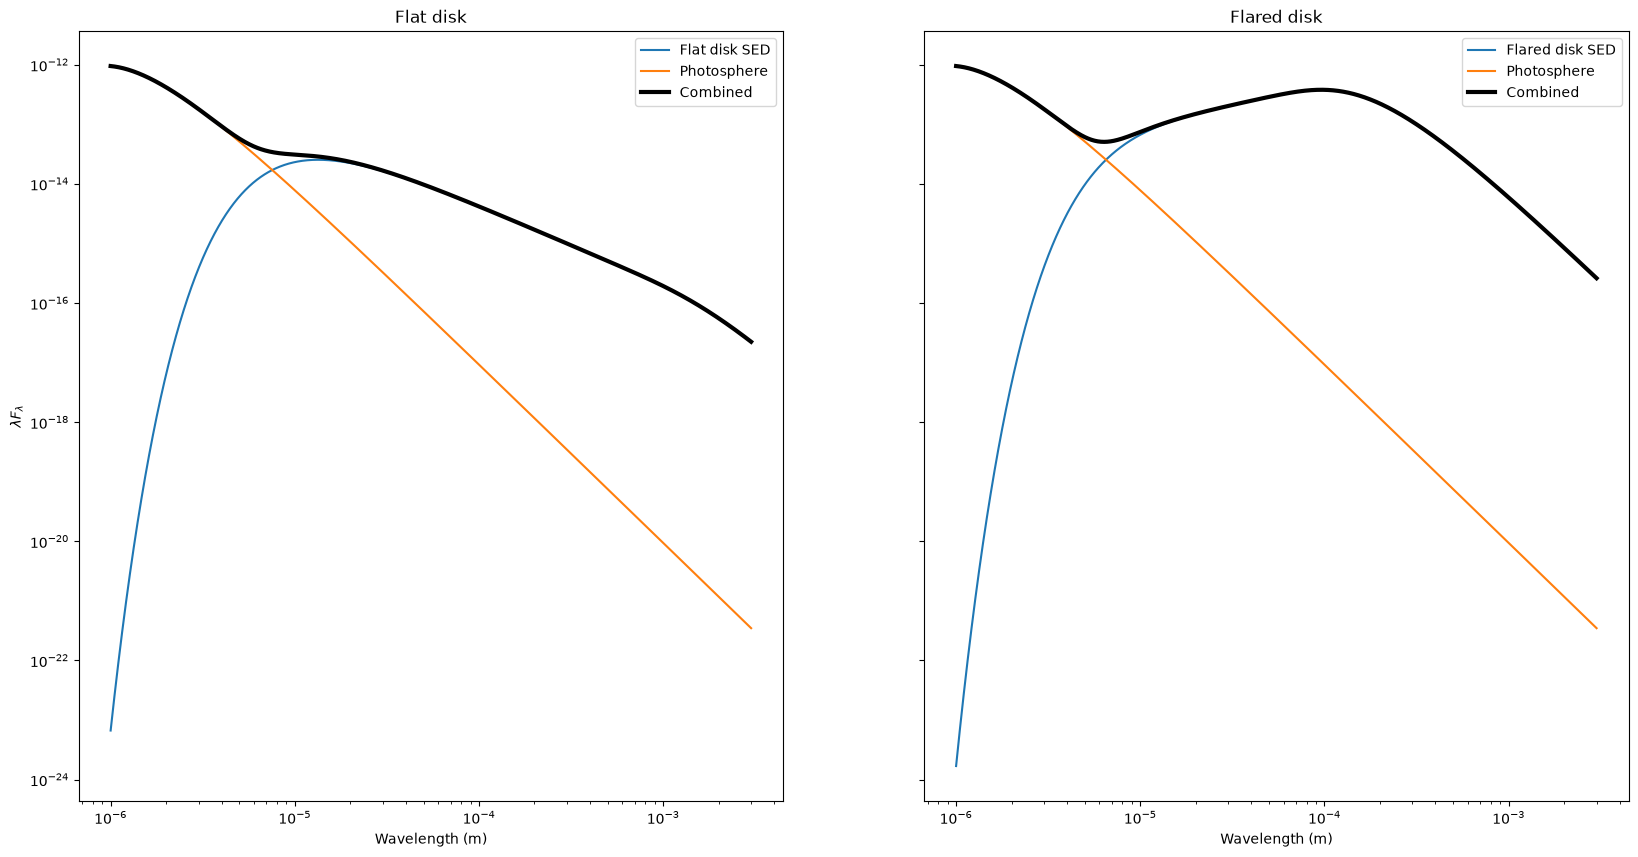

In [6]:
from astrotools.constants import R_SUN

r_edges = radial_grid(0.1*AU, 100*AU)
wavelengths = np.logspace(-6, np.log10(3e-3), 1000)
nus = C_LIGHT/wavelengths
distance = 150*PC

photosphere = np.pi * (2*R_SUN)**2 * np.asarray([planck_nu(nu, 4000) for nu in nus])/(distance**2)

def T_func_flat_disk(r):
    return temperature(r, t_1au = 81, slope = -3/4)

def T_func_flared_disk(r):
    return temperature(r, t_1au = 160, slope = -3/7)

F_flat = sed(nus, r_edges, T_func_flat_disk, distance)
F_flared = sed(nus, r_edges, T_func_flared_disk, distance)

fig, ax = plt.subplots(1, 2, figsize = (20, 10), sharey = True)
ax[0].plot(wavelengths, nus*F_flat, label = r'Flat disk SED')
ax[0].plot(wavelengths, nus*photosphere, label = r'Photosphere')
ax[0].plot(wavelengths, nus*F_flat + nus*photosphere, label = r'Combined', linewidth = 3, color = 'black')

ax[1].plot(wavelengths, nus*F_flared, label = r'Flared disk SED')
ax[1].plot(wavelengths, nus*photosphere, label = r'Photosphere')
ax[1].plot(wavelengths, nus*F_flared + nus*photosphere, label = r'Combined', linewidth = 3, color = 'black')

ax[0].set_xlabel(r'Wavelength (m)')
ax[1].set_xlabel(r'Wavelength (m)')
ax[0].set_ylabel(r'$\lambda F_{\lambda}$')
ax[0].legend()
ax[1].legend()
ax[0].set_yscale('log')
ax[0].set_xscale('log')
ax[1].set_yscale('log')
ax[1].set_xscale('log')

ax[0].set_title(r'Flat disk')
ax[1].set_title(r'Flared disk')

In [216]:
total_spectrum_flat = nus*F_flat + nus*photosphere
total_spectrum_flared = nus*F_flared + nus*photosphere

alpha_flat = (np.log(C_LIGHT/2.2e-6 * total_spectrum_flat[np.argmin(np.abs(wavelengths - 2.2e-6))]) - np.log(C_LIGHT/24e-6 * total_spectrum_flat[np.argmin(np.abs(wavelengths - 24e-6))]))/(np.log(2.2e-6) - np.log(24e-6))
alpha_flared = (np.log(C_LIGHT/2.2e-6 * total_spectrum_flared[np.argmin(np.abs(wavelengths - 2.2e-6))]) - np.log(C_LIGHT/24e-6 * total_spectrum_flared[np.argmin(np.abs(wavelengths - 24e-6))]))/(np.log(2.2e-6) - np.log(24e-6))

print(r"For the flat disk $\alpha_{IR}$ = ", alpha_flat, "and the power law value is:", -(4 - 2/(3/4)))
print(r"For the flared disk $\alpha_{IR}$ = ", alpha_flared, "and the power law value is:", -(4 - 2/(3/7)))

For the flat disk $\alpha_{IR}$ =  -2.191612716573747 and the power law value is: -1.3333333333333335
For the flared disk $\alpha_{IR}$ =  -1.2958227621594183 and the power law value is: 0.666666666666667


The value of $\alpha_{IR}$ measures the size of the infrared excess relative to the photosphere and NOT the disk's power law; so their values should be different. However, they are related as the infrared excess is inherently connected to the temperature distribution of the disk. I believe that the difference between their values has something to do with the temperature set at 1AU.

### Part (b)

In [ ]:
def flared_surface_density(r):
    return 0.01 * 1.7 * 1e4 * (r/AU)**(-3/2)

distance = 150*PC
F = sed(C_LIGHT/(1.3*1e-3), r_edges, T_func_flared_disk, distance, sigma_dust = flared_surface_density, kappa = dust_opacity)
M_dust = F * distance**2 / (dust_opacity(C_LIGHT/(1.3*1e-3)) * planck_nu(C_LIGHT/(1.3*1e-3), 20))

F_optically_thin = sed(C_LIGHT/(1.3*1e-3), r_edges, T_func_flared_disk, distance)
M_dust_optically_thin = F_optically_thin * distance**2 / (dust_opacity(C_LIGHT/(1.3*1e-3)) * planck_nu(C_LIGHT/(1.3*1e-3), 20))

print('By assuming the emission is optically thin, we get F = {} W.m^-2.Hz^-1, and M_dust = {} kg.'.format(F, M_dust))
print('Recomputing the flux with every annulus optically thin gives, F = {} W.m^-2.Hz^-1, and M_dust = {} kg.'.format(F_optically_thin, M_dust_optically_thin))

By assuming the emission is optically thin, we get F = 1.7778454635775452e-27 W.m^-2.Hz^-1, and M_dust = 6.768375900748223e+26 kg
Recomputing the flux with every annulus optically thin gives, F = 1.2407006032564807e-26 W.m^-2.Hz^-1, and M_dust = 4.723429699129565e+27 kg


The survery mass is smaller than the dust mass (by a factor of almost 10!), this must be a lower bound.

## 3. How a ring spreads

The grid resolution that leads to the least error is: 80
The grid resolutions with errors lower than 1 are: [35 36 37 38 39 40 41 42 43 44 45 46 47 48 49 50 51 52 53 54 55 56 57 58
 59 60 61 62 63 64 65 66 67 68 69 70 71 72 73 74 75 76 77 78 79 80]


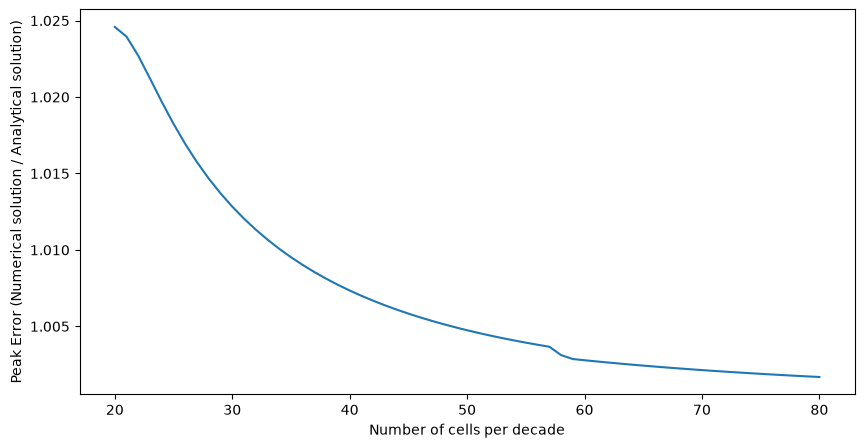

In [214]:
grid_resolutions = range(20, 81)
error = []

for g in grid_resolutions:
    grid = make_grid(1*AU, 1000*AU, g*3)
    viscosity = 1e11
    t = 0.1*(10*AU)**2/(12*viscosity)
    dt = cfl_timestep(grid, viscosity)

    evolve_output = evolve(ring_solution(grid.r, 0.1*t, M_EARTH, 10*AU, viscosity), grid, np.ones(len(grid.r)) * viscosity, t-0.1*t, dt)
    ring_solution_output = ring_solution(grid.r, t, M_EARTH, 10*AU, viscosity)

    error.append(np.max(evolve_output[1][-1])/np.max(ring_solution_output))

plt.figure(figsize = (10, 5))
plt.plot(grid_resolutions, error)
plt.xlabel('Number of cells per decade')
plt.ylabel('Peak Error (Numerical solution / Analytical solution)')

print('The grid resolution that leads to the least error is:', grid_resolutions[np.argmin(np.abs(np.asarray(error) - 1))])
mask = np.abs((np.asarray(error) - 1)) < 0.01
print('The grid resolutions with errors lower than 1 are:', np.asarray(grid_resolutions)[mask])

Note: I did not plot the above on log axes because it didn't really make sense for the range of values requested.

We can see that the order of convergence is exponential! To ensure a resolution of 1% or better, we need a grid resolution of at least 35 cells per decade.

### Part (b)

(0.1, 100.0)

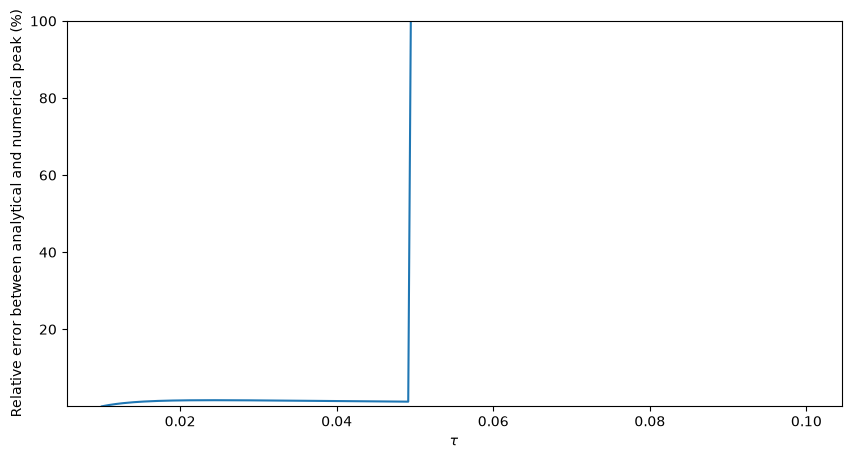

In [ ]:
grid = make_grid(1*AU, 1000*AU, 40*3)
viscosity = 1e11
t = 0.1*(10*AU)**2/(12*viscosity)
dt = 1.5*cfl_timestep(grid, viscosity, safety = 1)

evolve_output = evolve(ring_solution(grid.r, 0.1*t, M_EARTH, 10*AU, viscosity), grid, np.ones(len(grid.r)) * viscosity, t-0.1*t, 1.5*cfl_timestep(grid, viscosity, safety = 1))
ring_solution_output = np.asarray([ring_solution(grid.r, i, M_EARTH, 10*AU, viscosity) for i in 0.1*t + evolve_output[0]])

error = 100 * (np.abs(np.max(ring_solution_output, axis = 1) - np.max(evolve_output[1], axis = 1)))/np.max(ring_solution_output, axis = 1)
error_skyrocket_time = 0.1*t + evolve_output[0][np.where(error > 20)[0][0]]

plt.figure(figsize = (10, 5))
plt.plot(0.01 + evolve_output[0] * ((10*AU)**2/(12*viscosity))**(-1), error)
plt.xlabel(r'$\tau$')
plt.ylabel('Relative error between analytical and numerical peak (%)')
plt.ylim(1e-1, 1e2)

From this plot, we can see that the error skyrockets at $\tau = 0.05$, so let's explore what happens at that time.

Text(0, 0.5, '$\\Sigma$')

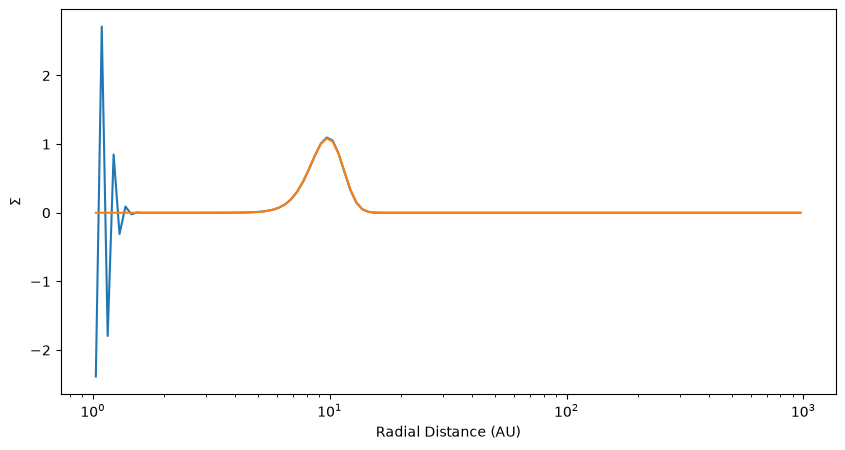

In [88]:
evolve_output = evolve(ring_solution(grid.r, 0.1*t, M_EARTH, 10*AU, viscosity), grid, np.ones(len(grid.r)) * viscosity, error_skyrocket_time-0.1*t, 1.5*cfl_timestep(grid, viscosity, safety = 1))
ring_solution_output = ring_solution(grid.r, error_skyrocket_time, M_EARTH, 10*AU, viscosity)

plt.figure(figsize = (10, 5))
plt.semilogx(grid.r/AU, evolve_output[1][-1], label = 'Numerical')
plt.semilogx(grid.r/AU, ring_solution_output, label = 'Analytical')
plt.xlabel('Radial Distance (AU)')
plt.ylabel(r'$\Sigma$')

From above, we can see that the run fails at the start of the grid (i.e. at small radial distances). This makes sense because the stability criterion for this numerical solution is a time step proportional to the square of the grid size. So, at smaller radial distances where the grid sizes are significantly smaller, a tiny step size is required for stability, hence why the code breaks at these locations.

### Part (c)

After $\tau = 0.1$, the error exceeds 1% at $\tau$ = []
The error is the largest when $\tau$ = 0.06471590909090909


Text(0, 0.5, 'Relative error between analytical and numerical peak (%)')

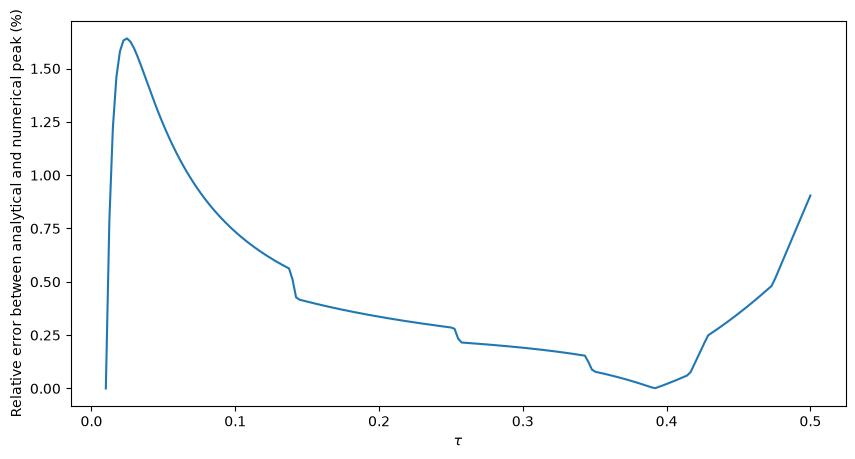

In [102]:
grid = make_grid(1*AU, 1000*AU, 40*3)
viscosity = 1e11
t = 0.5*(10*AU)**2/(12*viscosity)
dt = cfl_timestep(grid, viscosity)

evolve_output = evolve(ring_solution(grid.r, (0.01/0.5)*t, M_EARTH, 10*AU, viscosity), grid, np.ones(len(grid.r)) * viscosity, t-(0.01/0.5)*t, dt)
ring_solution_output = np.asarray([ring_solution(grid.r, i, M_EARTH, 10*AU, viscosity) for i in (0.01/0.5)*t + evolve_output[0]])

error = 100 * (np.abs(np.max(ring_solution_output, axis = 1) - np.max(evolve_output[1], axis = 1)))/np.max(ring_solution_output, axis = 1)
error_over1_time = 0.1*t + evolve_output[0][np.where((error > 1) & (evolve_output[0] * ((10*AU)**2/(12*viscosity))**(-1) > 0.1))[0]]
largest_error_time = 0.1*t + evolve_output[0][np.argmax(error)]

print(r'After $\tau = 0.1$, the error exceeds 1% at $\tau$ =', error_over1_time * ((10*AU)**2/(12*viscosity))**(-1))
print(r'The error is the largest when $\tau$ =', largest_error_time * ((10*AU)**2/(12*viscosity))**(-1))
plt.figure(figsize = (10, 5))
plt.plot(0.01 + evolve_output[0] * ((10*AU)**2/(12*viscosity))**(-1), error)
plt.xlabel(r'$\tau$')
plt.ylabel('Relative error between analytical and numerical peak (%)')

From above, we actually see that after $\tau = 0.1$ the error never exceeds 1%, but starts getting very close. The largest error actually happens at $\tau \approx 0.065$, close to the start of the run.

After $\tau = 0.1$, the error exceeds 1% at $\tau$ = []
The error is the largest when $\tau$ = 0.06469950631380979


Text(0, 0.5, 'Relative error between analytical and numerical peak (%)')

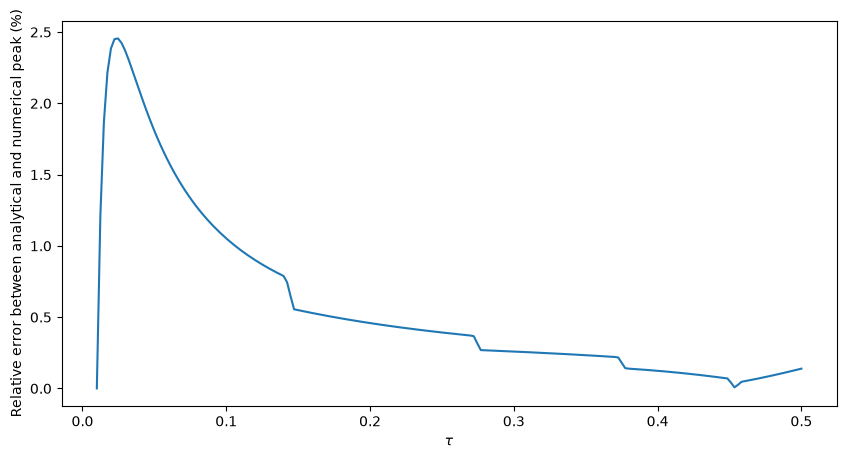

In [103]:
grid = make_grid(0.3*AU, 1000*AU, 40*3)
viscosity = 1e11
t = 0.5*(10*AU)**2/(12*viscosity)
dt = cfl_timestep(grid, viscosity)

evolve_output = evolve(ring_solution(grid.r, (0.01/0.5)*t, M_EARTH, 10*AU, viscosity), grid, np.ones(len(grid.r)) * viscosity, t-(0.01/0.5)*t, dt)
ring_solution_output = np.asarray([ring_solution(grid.r, i, M_EARTH, 10*AU, viscosity) for i in (0.01/0.5)*t + evolve_output[0]])

error = 100 * (np.abs(np.max(ring_solution_output, axis = 1) - np.max(evolve_output[1], axis = 1)))/np.max(ring_solution_output, axis = 1)
error_over1_time = 0.1*t + evolve_output[0][np.where((error > 1) & (evolve_output[0] * ((10*AU)**2/(12*viscosity))**(-1) > 0.1))[0]]
largest_error_time = 0.1*t + evolve_output[0][np.argmax(error)]

print(r'After $\tau = 0.1$, the error exceeds 1% at $\tau$ =', error_over1_time * ((10*AU)**2/(12*viscosity))**(-1))
print(r'The error is the largest when $\tau$ =', largest_error_time * ((10*AU)**2/(12*viscosity))**(-1))
plt.figure(figsize = (10, 5))
plt.plot(0.01 + evolve_output[0] * ((10*AU)**2/(12*viscosity))**(-1), error)
plt.xlabel(r'$\tau$')
plt.ylabel('Relative error between analytical and numerical peak (%)')

Once again, we see that the error is the largest at the same value of $\tau$ as above. However, when moving the inner edge closer, the error is much larger at that point and then decreases to lower values than above. 

## 4. Do the Lupus disks drain viscously?

### Part (a)

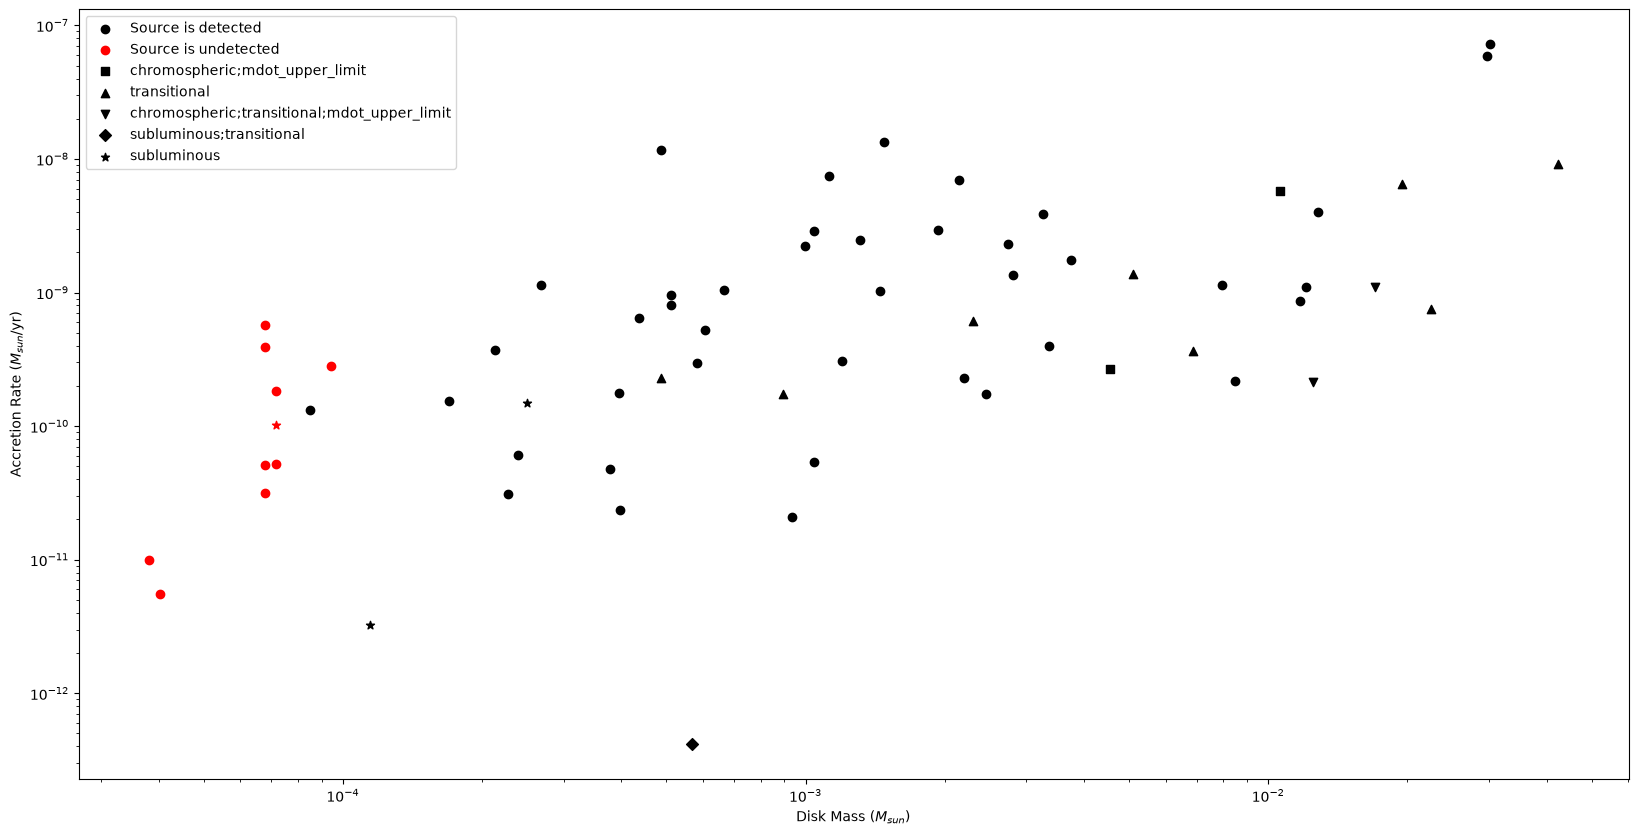

In [207]:
import pandas as pd
from astrotools.constants import PC, M_SUN

lupus_data = pd.read_csv("~/Desktop/astr5820/data/ps3/lupus_disks.csv")

F890 = lupus_data['F890_mJy'] * 1e-29
distance = lupus_data['distance_pc']*PC
M_dot = 10**(lupus_data["log_mdot"])

limits = lupus_data['F890_limit']

flags = lupus_data['flag']
flag_options = []
for elem in flags.dropna():
    if elem in flag_options:
        continue
    flag_options.append(elem)

markers = ['s', '^', 'v', 'D', '*', 'P', 'X', 'p', 'h']

nu = C_LIGHT/(890*1e-6)
kappa = 0.337
T_dust = 20

M_dust = F890 * distance**2/(kappa*planck_nu(nu, T_dust))
M_disk = 100*M_dust/M_SUN

plt.figure(figsize = (20, 10))

plt.scatter(M_disk[(limits == 0) & (flags.isna())], M_dot[(limits == 0) & (flags.isna())], color = 'black', label = 'Source is detected')
plt.scatter(M_disk[(limits == 1) & (flags.isna())], M_dot[(limits == 1) & (flags.isna())], color = 'red', label = 'Source is undetected')

for i in range(len(flag_options)):
    plt.scatter(M_disk[(limits == 0) & (flags == flag_options[i])], M_dot[(limits == 0) & (flags == flag_options[i])], color = 'black', label = flag_options[i], marker = markers[i])
    plt.scatter(M_disk[(limits == 1) & (flags == flag_options[i])], M_dot[(limits == 1) & (flags == flag_options[i])], color = 'red', marker = markers[i])

plt.xscale('log')
plt.yscale('log')
plt.ylabel(r'Accretion Rate ($M_{sun}$/yr)')
plt.xlabel(r'Disk Mass ($M_{sun}$)')
plt.legend()

### Part (b)

In [212]:
t_acc = M_disk[(limits == 0) & (flags.isna())]/M_dot[(limits == 0) & (flags.isna())]
print('The median accretion time is {:.2E} years.'.format(np.median(t_acc)))

gamma = 1
t_max = np.median(t_acc)/(2*(2-gamma)) #t_max = t + t_s

print('That median implies an upper limit on a disk age of {:.2E} years.'.format(t_max))

The median accretion time is 1.20E+06 years.
That median implies an upper limit on a disk age of 5.98E+05 years.


The upper limit is much smaller than the actual age of Lupus (600 kyr vs 1-3 Myr) which implies that the self similar solution is overestimating the accretion rate.

### Part (c)

See Problem 5 part 4. 

# Problem 5 Notebook

# Problem Set 3 — Watching a disk evolve
*ASTR 5820*

This notebook turns the viscous evolver you wrote in `step()` into figures and animations of two things: where a disk's mass goes, and where its angular momentum goes. The plotting and animation code is written for you. You fill in the cells marked **TODO**, eight short pieces, most of them a few lines, and answer three questions in one or two sentences each.

Before you start, `scale_height`, `sed` and `step` must be working; the notebook calls your `step()` throughout.

$$
\frac{\partial\Sigma}{\partial t} = \frac{3}{r}\frac{\partial}{\partial r}\left[r^{1/2}\frac{\partial}{\partial r}\left(\nu\Sigma r^{1/2}\right)\right],
\qquad
\dot M(r) = 6\pi r^{1/2}\frac{\partial}{\partial r}\left(\nu\Sigma r^{1/2}\right)\ \ (\text{positive inward}).
$$

The complete notebook runs in about two minutes. Each animation is saved to `figures/` as an MP4 and embedded below; without `ffmpeg` it is embedded frame by frame instead. Submit the notebook with its outputs.

In [268]:
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML, Video

from astrotools import constants as c
from astrotools.disk import structure as s
from astrotools.disk import viscous as v

step = v.step

BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e2dc"
plt.rcParams.update({
    "figure.dpi": 100, "font.size": 11, "axes.edgecolor": INK2, "axes.labelcolor": INK,
    "xtick.color": INK2, "ytick.color": INK2, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 2, "legend.frameon": False, "animation.embed_limit": 60,
})
os.makedirs("figures", exist_ok=True)

def show(anim, name, fps):
    # Save figures/<name>.mp4 and embed it; without ffmpeg, embed the frames instead.
    if animation.writers.is_available("ffmpeg"):
        path = f"figures/{name}.mp4"
        anim.save(path, writer=animation.FFMpegWriter(fps=fps, bitrate=1800), dpi=100)
        return Video(path, embed=True, html_attributes="controls loop")
    return HTML(anim.to_jshtml(fps=fps, default_mode="once"))

**TODO 1.** The animations show the mass flow through the disk, so you need $\dot M$ at every cell face. It is the flux your `step()` already computes.

In [269]:
def mdot_faces(sigma, grid, nu):
    q = v.pad_with_boundaries(nu * sigma * np.sqrt(grid.r))
    return 6 * np.pi * grid.r_face**0.5 * np.diff(q) / np.diff(grid.r_pad)

## 1. Why mass must move inward

Two rings of mass $m_1$ and $m_2$ orbit at $r_1 < r_2$ and trade angular momentum only with each other. With $s_i \equiv r_i^{1/2}$,

$$
J = \sqrt{GM_\star}\,(m_1 s_1 + m_2 s_2), \qquad E = -\frac{GM_\star}{2}\left(\frac{m_1}{s_1^2} + \frac{m_2}{s_2^2}\right).
$$

Move the inner ring by $\delta r_1$, let the outer ring move however it must to keep $J$ fixed, and see what happens to $E$.

**TODO 2.**

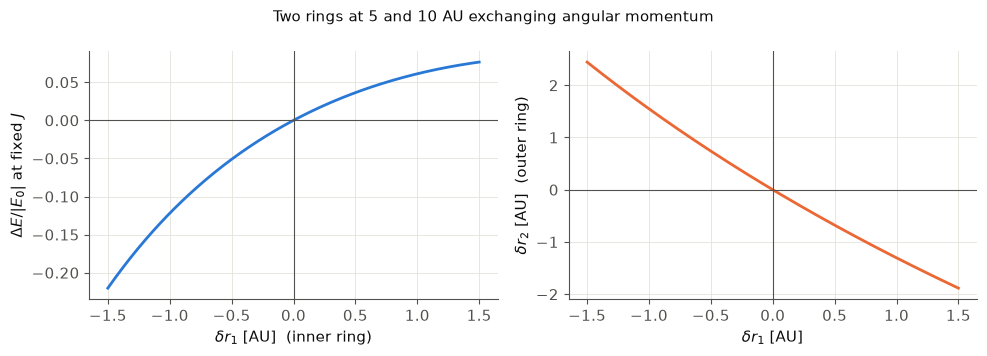

In [276]:
GM = c.GM_SUN
m1 = m2 = 1.0
r1, r2 = 5 * c.AU, 10 * c.AU
J0 = np.sqrt(GM) * (m1 * np.sqrt(r1) + m2 * np.sqrt(r2))
E0 = -GM / 2 * (m1 / r1 + m2 / r2)
dr1 = np.linspace(-1.5, 1.5, 301) * c.AU
r1n = r1 + dr1

# TODO: for each displacement of the inner ring, find the outer ring's radius r2n that keeps
#       J fixed, and the total energy E of the pair. Use the expressions above (s = r^(1/2)).
r2n = ((-m1 * np.sqrt(r1n) + J0/np.sqrt(GM))/m2)**2
E = - GM * (m1/r1n + m2/r2n)/2

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].plot(dr1 / c.AU, (E - E0) / abs(E0), color=BLUE)
ax[0].axhline(0, color=INK2, lw=0.8); ax[0].axvline(0, color=INK2, lw=0.8)
ax[0].set_xlabel(r"$\delta r_1$ [AU]  (inner ring)"); ax[0].set_ylabel(r"$\Delta E / |E_0|$ at fixed $J$")
ax[1].plot(dr1 / c.AU, (r2n - r2) / c.AU, color=ORANGE)
ax[1].axhline(0, color=INK2, lw=0.8); ax[1].axvline(0, color=INK2, lw=0.8)
ax[1].set_xlabel(r"$\delta r_1$ [AU]"); ax[1].set_ylabel(r"$\delta r_2$ [AU]  (outer ring)")
fig.suptitle("Two rings at 5 and 10 AU exchanging angular momentum", color=INK, fontsize=11)
fig.tight_layout()

## 2. A spreading ring

A ring at $r_0 = 10$ AU spreads with constant $\nu$, from $\tau = 0.004$ to 10, where $\tau = 12\nu t/r_0^2$. The animation shows mass and angular momentum per unit $\ln r$ (top) and the mass flow normalized to its largest value at each moment (bottom), with the stagnation radius, where the flow reverses, marked.

**TODO 3.** Fill in the time stepping.

In [274]:
r0, m_ring, nu0 = 10 * c.AU, 0.01 * c.M_SUN, 1.0e11
t_nu = r0 ** 2 / (12 * nu0)
g = v.make_grid(0.5 * c.AU, 3000 * c.AU, 113)                 # 30 cells per decade
nu_ring = np.full(g.n, nu0)
tau0, tau_end, n_frames = 0.004, 10.0, 100
taus = np.geomspace(tau0, tau_end, n_frames)
dt = v.cfl_timestep(g, nu_ring)

sig = v.ring_solution(g.r, tau0 * t_nu, m_ring, r0, nu0)
frames = [sig.copy()]
t_now = tau0 * t_nu
for tk in taus[1:]:
    # TODO: advance sig with your step() until t_now reaches tk * t_nu, using steps of at most dt
    #       and shortening the last one so the snapshot lands exactly on tk * t_nu.
    n_steps = int((tk * t_nu) // dt)
    last_step_size = (tk * t_nu) % dt
    for i in range(n_steps):
        sig = step(sig, g, nu_ring, dt)
    sig = step(sig, g, nu_ring, last_step_size)
    frames.append(sig.copy())
frames = np.array(frames)
j = np.sqrt(c.G * c.M_SUN * g.r)
M0, J0 = (frames[0] * g.area).sum(), (frames[0] * g.area * j).sum()

**TODO 4** (the profiles) and **TODO 5** (the stagnation radius, inside `draw`).

In [275]:
x = g.r / c.AU
# TODO: mass and angular momentum per unit ln r for a surface-density profile S, each divided by
#       its initial total (M0, J0). Mass per ln r is 2 pi r^2 Sigma; multiply by j for angular momentum.
dMdlnr = lambda S: 2*np.pi*(g.r)**2*S/M0
dJdlnr = lambda S: dMdlnr(S)*j/J0

fig, (a1, a2) = plt.subplots(2, 1, figsize=(8.0, 6.4), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
lM, = a1.semilogx(x, dMdlnr(frames[0]), color=BLUE, label=r"mass, $dM/d\ln r$")
lJ, = a1.semilogx(x, dJdlnr(frames[0]), color=ORANGE, label=r"angular momentum, $dJ/d\ln r$")
lA, = a1.semilogx(x, dMdlnr(v.ring_solution(g.r, tau0 * t_nu, m_ring, r0, nu0)), ":", color=INK, lw=1.2,
                  label="analytic (mass)")
a1.set_yscale("log"); a1.set_ylim(1e-4, 50); a1.set_xlim(1, 1000)
a1.set_ylabel("per unit ln r\n(normalized to initial total)"); a1.legend(loc="upper right", fontsize=9)
txt = a1.text(0.02, 0.92, "", transform=a1.transAxes, color=INK)
fr = a1.text(0.02, 0.80, "", transform=a1.transAxes, color=INK2, fontsize=10)
F0 = mdot_faces(frames[0], g, nu_ring)
lF, = a2.semilogx(g.r_face / c.AU, F0 / np.abs(F0).max(), color=AQUA)
a2.axhline(0, color=INK2, lw=0.8)
stag = a2.axvline(r0 / c.AU, color=INK2, ls="--", lw=1)
a2.set_ylim(-1.2, 1.2); a2.set_xlabel("r [AU]")
a2.set_ylabel(r"$\dot M(r)\,/\,\max|\dot M|$" "\n" r"+ inward, $-$ outward")
fig.tight_layout()

def draw(k):
    S = frames[k]
    lM.set_ydata(dMdlnr(S)); lJ.set_ydata(dJdlnr(S))
    lA.set_ydata(dMdlnr(v.ring_solution(g.r, taus[k] * t_nu, m_ring, r0, nu0)))
    F = mdot_faces(S, g, nu_ring)
    lF.set_ydata(F / np.abs(F).max())
    # TODO: the stagnation radius r_st in AU, where F changes from inward (> 0) to outward (<= 0).
    #       If F crosses more than once, take the crossing with the largest jump in F.
    sign_changes = np.where((F[:-1] > 0) & (F[1:] <= 0))[0]
    location_of_biggest_sign_change = np.argmax(np.abs(np.diff(F)[sign_changes]))
    r_st = g.r_face[location_of_biggest_sign_change] - F[location_of_biggest_sign_change] * (g.r_face[location_of_biggest_sign_change+1] - g.r_face[location_of_biggest_sign_change]) / (F[location_of_biggest_sign_change+1] - F[location_of_biggest_sign_change])
    stag.set_xdata([r_st, r_st])
    txt.set_text(fr"$\tau$ = {taus[k]:.3f}   (t = {taus[k] * t_nu / c.YR:,.0f} yr)")
    fr.set_text(f"accreted: {1 - (S * g.area).sum() / M0:5.1%} of mass, "
                f"{1 - (S * g.area * j).sum() / J0:5.1%} of J;  stagnation radius {r_st:.1f} AU")
    return lM, lJ, lA, lF, stag, txt, fr

anim = animation.FuncAnimation(fig, draw, frames=len(taus), interval=80)
plt.close(fig)
show(anim, "spreading_ring", fps=12)

**Question A.** By $\tau = 10$, what fractions of the ring's mass and of its angular momentum have reached the star? Explain in one or two sentences why the two fractions differ.

*Your answer:* 73% of the mass have reached the star while only 16% of its angular momentum reached the star. This is because momentum moves away from the disk during its evolution while mass moves into the disk.

## 3. The long-time limit

The analytic solution can be followed much longer than the grid. Track three quantities to $\tau = 1000$, each as a fraction of the ring's initial mass or angular momentum: the mass that has reached the star, the angular momentum outside $2r_0$, and the mass outside $2r_0$.

**TODO 6.**

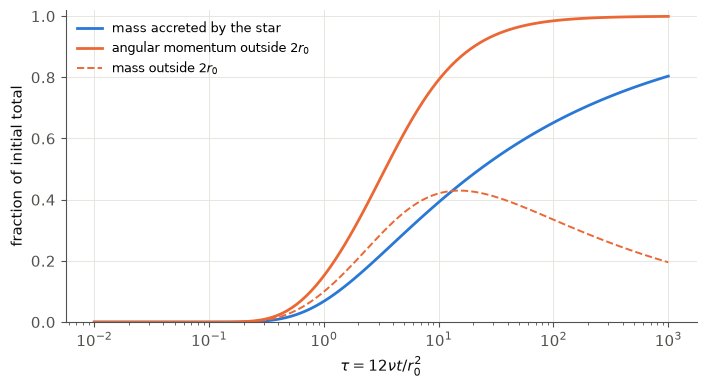

In [279]:
rr = np.geomspace(1e-6, 1e5, 60000) * r0
jj = np.sqrt(c.G * c.M_SUN * rr)
ann = np.pi * np.diff(np.concatenate(([0], np.sqrt(rr[1:] * rr[:-1]), [rr[-1] * 1.0002])) ** 2)
J_ring = m_ring * np.sqrt(c.G * c.M_SUN * r0)
tau_long = np.geomspace(1e-2, 1e3, 120)
f_acc, f_j_out, f_m_out = [], [], []
for tk in tau_long:
    S = v.ring_solution(rr, tk * t_nu, m_ring, r0, nu0)
    m_i = S * ann                     # mass in each annulus
    J_i = m_i * jj                    # angular momentum in each annulus
    # TODO: append, as fractions of the ring's INITIAL mass m_ring and angular momentum J_ring,
    #       the mass that has reached the star (whatever is no longer on the grid), the angular
    #       momentum outside 2 r0, and the mass outside 2 r0.
    f_acc.append(1 - np.sum(m_i)/m_ring)
    f_j_out.append(np.sum(J_i[rr > 2*r0])/J_ring) 
    f_m_out.append(np.sum(m_i[rr > 2*r0])/m_ring) 

fig, ax = plt.subplots(figsize=(7.2, 4.0))
ax.semilogx(tau_long, f_acc, color=BLUE, label="mass accreted by the star")
ax.semilogx(tau_long, f_j_out, color=ORANGE, label=r"angular momentum outside $2r_0$")
ax.semilogx(tau_long, f_m_out, color=ORANGE, ls="--", lw=1.4, label=r"mass outside $2r_0$")
ax.set_xlabel(r"$\tau = 12\nu t / r_0^2$"); ax.set_ylabel("fraction of total")
ax.set_ylabel("fraction of initial total")
ax.set_ylim(0, 1.02); ax.legend(fontsize=9, loc="upper left"); fig.tight_layout()

**Question B.** At $\tau = 1000$, what fraction of the angular momentum is outside $2r_0$, and what fraction of the mass? How do the two curves behave as $\tau$ grows, and what does that say about where the mass and the angular momentum end up as $\tau \to \infty$?

*Your answer:* At $\tau = 1000$, all of the angular momentum is outside $2r_0$ while only 20% of the mass is outside $2r_0$. As $\tau$ grows, the angular momentum curve grows somewhat logarithmically (steeply at first and then levels out), while the mass curve grows quite quickly before peaking at around $\tau = 10$ and decreasing after. So, as $\tau \to \infty$ the angular momentum ends up outside of the disk while the mass ends up in the star.

## 4. An $\alpha$ disk over 10 Myr

This is the run of Problem 4(c): $\alpha = 10^{-3}$, $T = 280\,(r/{\rm AU})^{-1/2}$ K, $r_1 = 30$ AU and $M_0 = 0.05\,M_\odot$. The animation shows $\Sigma(r)$ against the analytic solution, the mass flow normalized to the accretion rate onto the star, and $M(t)$ and $\dot M_\star(t)$ against the expressions in the handout. The dashed line marks the analytic radius where the flow reverses, $r_1\tilde t/2$ with $\tilde t = 1 + t/t_s$. Use this run and its figure for your answer to 4(c).

**TODO 7.**

In [273]:
alpha, r1, M0d = 1e-3, 30 * c.AU, 0.05 * c.M_SUN

# TODO: the run of Problem 4(c). Build the grid (0.1 to 1e4 AU, 20 cells per decade), the alpha
#       viscosity nud on it, nu1 = nu(r1) and t_s; start from similarity_solution at t = 0 and call
#       v.evolve to 10 Myr with n_out = 100 snapshots. Keep the names used below.
gd = v.make_grid(0.1*c.AU, 1e4*c.AU, 20*5); nud = v.alpha_viscosity(gd.r, alpha, s.temperature); nu1 = v.alpha_viscosity(r1, alpha, s.temperature); t_s = r1**2 / (3 * nu1)
dt = v.cfl_timestep(gd, nud)
t_d, sig_d, mass_d = v.evolve(v.similarity_solution(gd.r, 0, M0d, r1, nu1, gamma=1.0), gd, nud, 10*c.MYR, dt, n_out=100)

mdot_star = np.array([mdot_faces(S_, gd, nud)[0] for S_ in sig_d])      # through the inner edge
print(f"t_s = {t_s / c.MYR:.2f} Myr")

t_s = 1.43 Myr


In [277]:
SIG_UNIT = 10.0                      # kg/m^2 -> g/cm^2
yr_msun = c.YR / c.M_SUN
xd, tm, Tt = gd.r / c.AU, t_d / c.MYR, 1 + t_d / t_s
fig = plt.figure(figsize=(10, 6.2))
gs = fig.add_gridspec(2, 2, width_ratios=[1.6, 1], height_ratios=[1.4, 1])
aS = fig.add_subplot(gs[0, 0]); aF = fig.add_subplot(gs[1, 0], sharex=aS)
aM = fig.add_subplot(gs[0, 1]); aR = fig.add_subplot(gs[1, 1], sharex=aM)

aS.loglog(xd, sig_d[0] / SIG_UNIT, color=INK2, lw=1, alpha=0.5, label="t = 0")
lS, = aS.loglog(xd, sig_d[0] / SIG_UNIT, color=BLUE, label="step()")
lSa, = aS.loglog(xd, sig_d[0] / SIG_UNIT, ":", color=INK, lw=1.2, label="analytic")
aS.set_xlim(0.1, 3000); aS.set_ylim(1e-3, 3e3)
aS.set_ylabel(r"$\Sigma$ [g cm$^{-2}$]"); aS.legend(fontsize=9, loc="lower left")
tS = aS.text(0.97, 0.95, "", transform=aS.transAxes, ha="right", va="top", color=INK)
lF, = aF.semilogx(gd.r_face / c.AU, mdot_faces(sig_d[0], gd, nud) / mdot_star[1], color=AQUA)
aF.axhline(0, color=INK2, lw=0.8)
rrev = aF.axvline(r1 / 2 / c.AU, color=INK2, ls="--", lw=1)
aF.set_ylim(-0.6, 1.3); aF.set_xlabel("r [AU]")
aF.set_ylabel(r"$\dot M(r)\,/\,\dot M_\star(t)$" "\n" r"+ inward")
aM.plot(tm, M0d * Tt ** -0.5 / c.M_SUN, ":", color=INK, lw=1.2)
aM.plot(tm, mass_d / c.M_SUN, color=BLUE, lw=1, alpha=0.35)
lMt, = aM.plot(tm[:1], mass_d[:1] / c.M_SUN, color=BLUE)
aM.set_ylabel(r"disk mass [$M_\odot$]"); aM.set_ylim(0, 0.055)
aR.semilogy(tm, 3 * nu1 * M0d / (2 * r1 ** 2) * Tt ** -1.5 * yr_msun, ":", color=INK, lw=1.2, label="analytic")
aR.semilogy(tm[1:], mdot_star[1:] * yr_msun, color=AQUA, lw=1, alpha=0.35)
lRt, = aR.semilogy(tm[1:2], mdot_star[1:2] * yr_msun, color=AQUA, label="onto the star")
aR.set_xlabel("t [Myr]"); aR.set_ylabel(r"$\dot M_\star$ [$M_\odot$ yr$^{-1}$]")
aR.set_ylim(3e-10, 5e-8); aR.legend(fontsize=9)
fig.tight_layout()

def draw_d(k):
    S = sig_d[k]; kk = max(k, 1)
    lS.set_ydata(S / SIG_UNIT)
    lSa.set_ydata(v.similarity_solution(gd.r, t_d[k], M0d, r1, nu1) / SIG_UNIT)
    lF.set_ydata(mdot_faces(S, gd, nud) / mdot_star[kk])
    r_rev = r1 * Tt[k] / 2 / c.AU
    rrev.set_xdata([r_rev, r_rev])
    lMt.set_data(tm[:k + 1], mass_d[:k + 1] / c.M_SUN)
    lRt.set_data(tm[1:kk + 1], mdot_star[1:kk + 1] * yr_msun)
    tS.set_text(f"t = {tm[k]:.1f} Myr\nM = {mass_d[k] / c.M_SUN:.3f} $M_\\odot$")
    return lS, lSa, lF, rrev, lMt, lRt, tS

anim_d = animation.FuncAnimation(fig, draw_d, frames=len(t_d), interval=90)
plt.close(fig)
show(anim_d, "alpha_disk", fps=10)

## 5. Viscous timescales

The time to rearrange the disk over a radius $r$ is $t_\nu = r^2/\nu$. Compare it with the 1–3 Myr lifetimes of observed disks.

**TODO 8.**

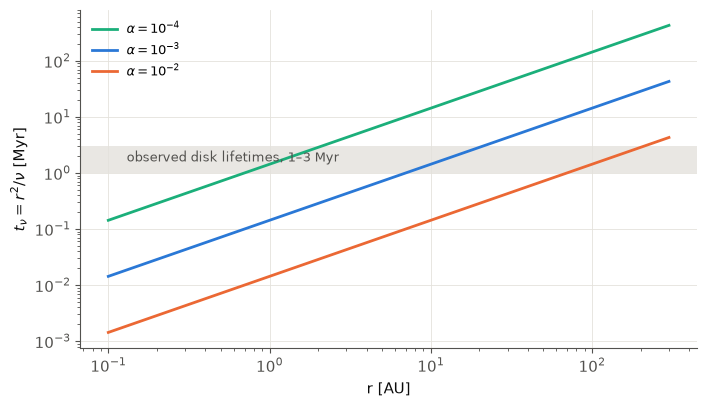

In [278]:
r_ax = np.geomspace(0.1, 300, 200) * c.AU
fig, ax = plt.subplots(figsize=(7.2, 4.2))
ax.axhspan(1, 3, color=GRID, alpha=0.8, lw=0)
ax.text(0.13, 1.6, "observed disk lifetimes, 1–3 Myr", color=INK2, fontsize=9)
for a_, col in [(1e-4, AQUA), (1e-3, BLUE), (1e-2, ORANGE)]:
    tnu = (r_ax**2/v.alpha_viscosity(r_ax, a_, s.temperature))/c.MYR      # TODO: viscous time r^2 / nu in Myr at each radius in r_ax
    ax.loglog(r_ax / c.AU, tnu, color=col, label=fr"$\alpha = 10^{{{int(np.log10(a_))}}}$")
ax.set_xlabel("r [AU]"); ax.set_ylabel(r"$t_\nu = r^2/\nu$ [Myr]")
ax.legend(fontsize=9, loc="upper left"); fig.tight_layout()

**Question C.** Which of the three values of $\alpha$, applied to the whole disk, is consistent with disks surviving 1–3 Myr out to tens of AU? One sentence.

*Your answer:* $\alpha = 10^{-2}$ as it's the only one that doesn't go over the observed disk lifetimes at tens of AU.